In [1]:
# Import pandas for data analysis
import pandas as pd

# Load the CFPB credit card complaints dataset
df = pd.read_excel("CFPB_credit_card_complaints_with_narratives_2015_2017.xlsx")

# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Display the first five rows
df.head()

Dataset shape: (18276, 18)


,Date received,Product,Sub-product,Issue,Sub-issue,Consumer complaint narrative,Company public response,Company,State,ZIP code,Tags,Consumer consent provided?,Submitted via,Date sent to company,Company response to consumer,Timely response?,Consumer disputed?,Complaint ID
0,2017-03-04,Credit card,NaN,Balance transfer,NaN,Around XX/XX/XXXX I accepted a credit card off...,NaN,JPMORGAN CHASE & CO.,TN,376XX,Older American,Consent provided,Web,2017-03-04,Closed with monetary relief,Yes,No,2371616
1,2017-04-05,Credit card,NaN,Identity theft / Fraud / Embezzlement,NaN,My business debit cards were stolen from my ma...,Company has responded to the consumer and the ...,"BANK OF AMERICA, NATIONAL ASSOCIATION",CA,958XX,NaN,Consent provided,Web,2017-04-05,Closed with monetary relief,Yes,No,2420310
2,2017-04-10,Credit card,NaN,Other fee,NaN,I applied for a MasterCard through Barclaycard...,Company has responded to the consumer and the ...,BARCLAYS BANK DELAWARE,VA,234XX,Servicemember,Consent provided,Web,2017-04-10,Closed with explanation,Yes,No,2426957
3,2017-03-04,Credit card,NaN,Payoff process,NaN,I have paid the entire balance off of this car...,NaN,JPMORGAN CHASE & CO.,NJ,087XX,Older American,Consent provided,Web,2017-03-04,Closed with non-monetary relief,Yes,No,2371956
4,2017-04-13,Credit card,NaN,Billing disputes,NaN,I 'm currently serving on XXXX in the XXXX. I ...,Company has responded to the consumer and the ...,BARCLAYS BANK DELAWARE,CA,932XX,Servicemember,Consent provided,Web,2017-04-13,Closed with explanation,Yes,No,2433297


In [2]:
# Check missing values in each column
missing_values = df.isnull().sum()

# Display missing values from highest to lowest
print("Missing Values by Column:")
print(missing_values.sort_values(ascending=False))

Missing Values by Column:
Sub-issue                       18276
Sub-product                     18276
Tags                            15321
Company public response          8990
ZIP code                           52
State                              52
Product                             0
Date received                       0
Consumer complaint narrative        0
Issue                               0
Company                             0
Consumer consent provided?          0
Submitted via                       0
Date sent to company                0
Company response to consumer        0
Timely response?                    0
Consumer disputed?                  0
Complaint ID                        0
dtype: int64


When I checked the missing data, I discovered that State and ZIP Code had 52 missing values, while Tags had 15,321 missing values. These do not affect our analysis because we are not analyzing complaints by state or ZIP code, and we are not using Tags for classification.

In [3]:
# Check for duplicate complaint IDs
print("Duplicate Complaint IDs:", df["Complaint ID"].duplicated().sum())

# Check for completely duplicated rows
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Complaint IDs: 0
Duplicate Rows: 0


In [4]:
# Create a copy of the original dataset
df_clean = df.copy()

# Remove columns that are completely empty
df_clean = df_clean.drop(columns=["Sub-issue", "Sub-product"])

# Convert the date column to datetime format
df_clean["Date received"] = pd.to_datetime(df_clean["Date received"])

# Check the cleaned dataset
print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)

# Check that all complaint IDs are still unique
print("Duplicate Complaint IDs:", df_clean["Complaint ID"].duplicated().sum())

Original dataset: (18276, 18)
Cleaned dataset: (18276, 16)
Duplicate Complaint IDs: 0


In [5]:
# Count the number of complaints in each issue category
issue_counts = df_clean["Issue"].value_counts()

# Display the 10 most common complaint issues
print("Top 10 Credit Card Complaint Issues:")
print(issue_counts.head(10))

Top 10 Credit Card Complaint Issues:
Issue
Billing disputes                         2973
Other                                    1890
Identity theft / Fraud / Embezzlement    1672
Closing/Cancelling account               1396
Customer service / Customer relations     946
Rewards                                   876
Delinquent account                        812
Advertising and marketing                 800
APR or interest rate                      774
Late fee                                  751
Name: count, dtype: int64


In [6]:
# Examine the first 5 complaints classified as "Other"

other_complaints = df_clean[df_clean["Issue"] == "Other"]

# Display the complaint narratives
other_complaints["Consumer complaint narrative"].head(5)

,Consumer complaint narrative
14,"I have a XXXX, Wells Fargo App barely works, I..."
29,"Hi, I am one of the many military members who ..."
39,I am filling a a series complaint against the ...
93,On XX/XX/XXXX I sent out a certified letter to...
94,I had a Nordstrom credit card which charged of...


In [7]:
# Display the full text of the first 3 complaints classified as "Other"

for index, complaint in other_complaints["Consumer complaint narrative"].head(3).items():
    print(f"\nComplaint {index}")
    print(complaint)
    print("-" * 80)


Complaint 14
I have a XXXX, Wells Fargo App barely works, I submitted a payment thru the app that was never posted after everything I received {$37.00} late fee and a {$70.00} interest charged. I called on XXXX/XXXX/17 and they assigned me a executive because I said that I was going to file a formal complaint because. After this they told me to wait until they can help waived this for so I made a payment on the XXXX
--------------------------------------------------------------------------------

Complaint 29
Hi, I am one of the many military members who was offered Barclay 's XXXX XXXX XXXX a MasterCard credit card ) with the waived annual fee of {$990.00} because I was on XXXX XXXX. Unfortunately, I just received a letter from Barclay 's that says they are changing their policy and will now be charging the standard {$990.00} fee. My primary complaint is this appears to be a blatant " bait and switch '' tactic which will have an impact on my personal finances. If Barclay 's would hav

In [8]:
# Select 10 random complaints classified as "Other"
sample_other = other_complaints.sample(n=10, random_state=42)

# Display the first 250 characters of each complaint
for index, complaint in sample_other["Consumer complaint narrative"].items():
    print(f"Complaint {index}: {complaint[:250]}")
    print("-" * 60)

Complaint 12054: The Home Depot/CBNA account # XXXX is showing a negative 30 day mark on my credit report for XXXX. I have called them to dispute this multiple times as I was not aware that a payment had not processed. As previously stated to them, this was set up on
------------------------------------------------------------
Complaint 10299: On XXXX XXXX, 2016 I applied for a credit card with Penfed Credit Union. I received an email from Penfed stating that my XXXX credit report was locked. On XXXX XXXX, 2016 I removed the lock from my XXXX credit report. Penfed subsequently approved the
------------------------------------------------------------
Complaint 16920: On XXXX XXXX, XXXX amex took my payment 2x. I have yet to receive a refund. 
New amex card, XXXX XXXX. 
XXXX XXXX, XXXX - became aware that auto pay was not setup. Made 2 payments to catch up. Spoke with Amex rep to clarify that this was a miscommuni
------------------------------------------------------------
Complaint 172

In [9]:
# Display all complaint issue categories and their frequencies

issue_categories = df_clean["Issue"].value_counts()

print("Total number of issue categories:", len(issue_categories))

print("\nAll Issue Categories:")
print(issue_categories.to_string())

Total number of issue categories: 30

All Issue Categories:
Issue
Billing disputes                            2973
Other                                       1890
Identity theft / Fraud / Embezzlement       1672
Closing/Cancelling account                  1396
Customer service / Customer relations        946
Rewards                                      876
Delinquent account                           812
Advertising and marketing                    800
APR or interest rate                         774
Late fee                                     751
Credit card protection / Debt protection     690
Transaction issue                            660
Billing statement                            606
Payoff process                               501
Credit determination                         493
Other fee                                    480
Unsolicited issuance of credit card          478
Credit line increase/decrease                436
Balance transfer                             293
Pri

In [10]:
# Count the number of complaints received each year

complaints_by_year = df_clean["Date received"].dt.year.value_counts().sort_index()

# Display the results
print("Credit Card Complaints by Year:")
print(complaints_by_year)

Credit Card Complaints by Year:
Date received
2015    6247
2016    9438
2017    2591
Name: count, dtype: int64


In [11]:
# Check the date range covered by each year

date_coverage = df_clean.groupby(
    df_clean["Date received"].dt.year
)["Date received"].agg(["min", "max", "count"])

print("Date Coverage by Year:")
print(date_coverage)

Date Coverage by Year:
                     min        max  count
Date received                             
2015          2015-03-19 2015-12-31   6247
2016          2016-01-01 2016-12-31   9438
2017          2017-01-01 2017-04-17   2591


In [12]:
# Count complaints received each month
complaints_by_month = (
    df_clean.groupby(
        df_clean["Date received"].dt.to_period("M")
    )
    .size()
)

# Display monthly complaint counts
print("Monthly Credit Card Complaints:")
print(complaints_by_month)

Monthly Credit Card Complaints:
Date received
2015-03    248
2015-04    572
2015-05    697
2015-06    650
2015-07    701
2015-08    660
2015-09    668
2015-10    689
2015-11    693
2015-12    669
2016-01    710
2016-02    707
2016-03    712
2016-04    717
2016-05    689
2016-06    685
2016-07    800
2016-08    873
2016-09    974
2016-10    952
2016-11    780
2016-12    839
2017-01    881
2017-02    773
2017-03    719
2017-04    218
Freq: M, dtype: int64


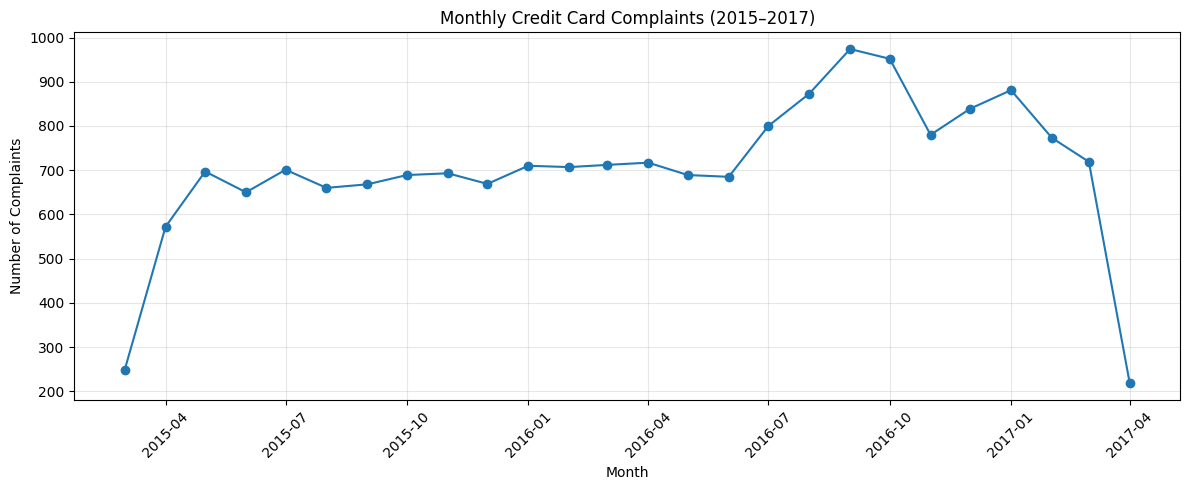

In [13]:
# Import matplotlib for visualization
import matplotlib.pyplot as plt

# Convert monthly periods to dates for plotting
monthly_dates = complaints_by_month.index.to_timestamp()

# Create a line chart
plt.figure(figsize=(12, 5))

plt.plot(monthly_dates, complaints_by_month.values, marker="o")

# Add title and labels
plt.title("Monthly Credit Card Complaints (2015–2017)")
plt.xlabel("Month")
plt.ylabel("Number of Complaints")

# Improve readability
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Display the chart
plt.show()

In [14]:
# Compare complaint issues between the first and second halves of 2016

# First half: January to June 2016
period_1 = df_clean[
    (df_clean["Date received"] >= "2016-01-01") &
    (df_clean["Date received"] < "2016-07-01")
]

# Second half: July to December 2016
period_2 = df_clean[
    (df_clean["Date received"] >= "2016-07-01") &
    (df_clean["Date received"] < "2017-01-01")
]

# Calculate average monthly complaints by issue
comparison = pd.DataFrame({
    "Jan-Jun Avg/Month": period_1["Issue"].value_counts() / 6,
    "Jul-Dec Avg/Month": period_2["Issue"].value_counts() / 6
}).fillna(0)

# Calculate the change in average monthly complaints
comparison["Monthly Increase"] = (
    comparison["Jul-Dec Avg/Month"] -
    comparison["Jan-Jun Avg/Month"]
)

# Display the 10 issues with the largest increases
print("Top 10 Issues with Increased Monthly Complaints:")

print(
    comparison.sort_values(
        "Monthly Increase", ascending=False
    ).head(10).round(1)
)

Top 10 Issues with Increased Monthly Complaints:
                                          Jan-Jun Avg/Month  \
Issue                                                         
Billing disputes                                      118.2   
Other                                                  71.2   
Rewards                                                33.7   
Transaction issue                                      19.5   
Credit card protection / Debt protection               20.3   
Unsolicited issuance of credit card                    14.2   
Identity theft / Fraud / Embezzlement                  66.7   
Closing/Cancelling account                             54.8   
Customer service / Customer relations                  35.0   
Credit determination                                   16.2   

                                          Jul-Dec Avg/Month  Monthly Increase  
Issue                                                                          
Billing disputes                  

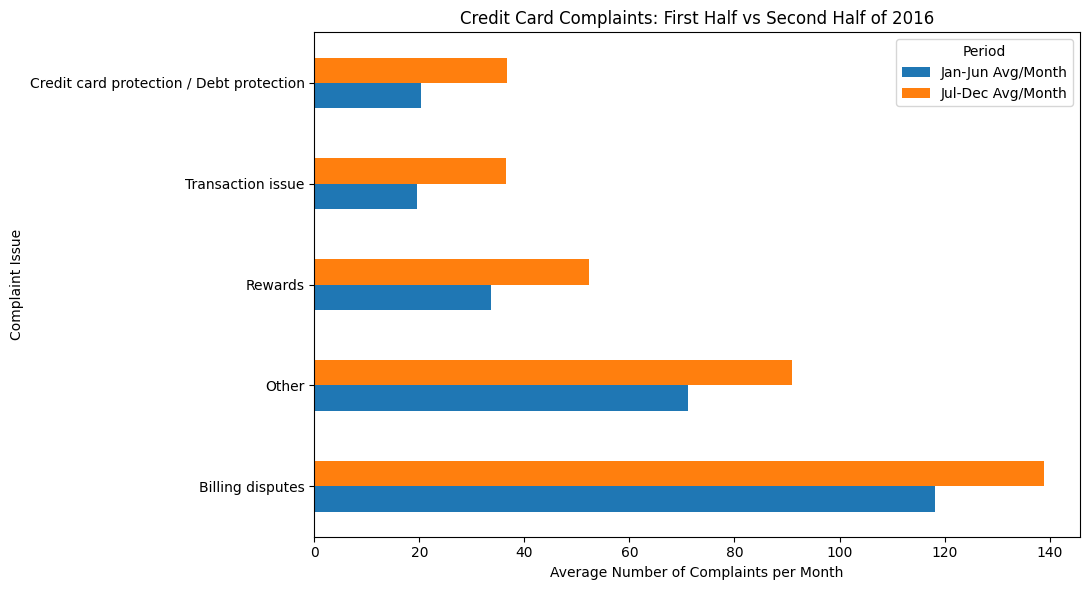

In [15]:
# Select the five complaint categories with the largest increases
top_5_increases = comparison.sort_values(
    "Monthly Increase", ascending=False
).head(5)

# Create a comparison chart
top_5_increases[
    ["Jan-Jun Avg/Month", "Jul-Dec Avg/Month"]
].plot(kind="barh", figsize=(11, 6))

# Add chart title and labels
plt.title("Credit Card Complaints: First Half vs Second Half of 2016")
plt.xlabel("Average Number of Complaints per Month")
plt.ylabel("Complaint Issue")

# Improve chart appearance
plt.legend(title="Period")
plt.tight_layout()
plt.show()

In [16]:
# Validate the cleaned CFPB dataset

# Check that no complaints were lost during cleaning
assert len(df_clean) == len(df), "Some complaints were lost!"

# Check that complaint IDs are unique
assert df_clean["Complaint ID"].is_unique, "Duplicate complaint IDs found!"

# Check that important columns have no missing values
assert df_clean["Consumer complaint narrative"].notna().all(), "Missing narratives found!"
assert df_clean["Issue"].notna().all(), "Missing issue labels found!"
assert df_clean["Date received"].notna().all(), "Missing dates found!"

print("All data validation checks passed!")

All data validation checks passed!


### Exploratory Data Analysis: Key Findings

**Dataset:** CFPB credit card complaints, March 2015–April 2017.

**Data preparation**
- The original dataset contained 18,276 complaints and 18 columns.
- Removed two completely empty columns: Sub-issue and Sub-product.
- No duplicate complaint IDs or duplicate rows were found.
- All 18,276 complaints were retained.
- All data validation checks passed.

**Key findings**
1. Billing disputes were the most common complaint category, with 2,973 complaints.
2. The "Other" category contained 1,890 complaints. A preliminary review suggested that it includes several different types of customer concerns.
3. The dataset contains 30 complaint categories.
4. September 2016 recorded the highest monthly complaint count, with 974 complaints.
5. Comparing January–June with July–December 2016, billing disputes had the largest increase in average monthly complaints, followed by Other and Rewards.

**Limitations**

The dataset covers only part of 2015 and 2017. Therefore, annual complaint totals should not be compared without considering the incomplete periods.

The analysis describes complaint patterns but does not establish why complaint volumes changed.

**Next stage**

Integrate these findings with the AI classification and evaluation workflow for the final project.


In [17]:
# Map the 30 CFPB issue categories to Hunter's 8 broader categories

CATEGORY_ISSUES = {
    "billing_dispute": [
        "Billing disputes", "Billing statement", "Transaction issue"
    ],
    "fees_interest": [
        "APR or interest rate", "Late fee", "Other fee",
        "Balance transfer fee", "Cash advance fee", "Overlimit fee"
    ],
    "fraud_identity": [
        "Identity theft / Fraud / Embezzlement",
        "Unsolicited issuance of credit card", "Privacy"
    ],
    "account_management": [
        "Closing/Cancelling account", "Credit line increase/decrease",
        "Credit determination", "Application processing delay",
        "Payoff process", "Sale of account", "Balance transfer",
        "Cash advance", "Convenience checks"
    ],
    "collections_hardship": [
        "Delinquent account", "Bankruptcy",
        "Forbearance / Workout plans", "Arbitration"
    ],
    "customer_service": [
        "Customer service / Customer relations"
    ],
    "rewards_marketing": [
        "Rewards", "Advertising and marketing",
        "Credit card protection / Debt protection"
    ],
    "other": ["Other"]
}

# Create a lookup from each original issue to its broader category
issue_to_category = {
    issue: category
    for category, issues in CATEGORY_ISSUES.items()
    for issue in issues
}

# Add Hunter's categories to our cleaned dataset
df_clean["AI_Category"] = df_clean["Issue"].map(issue_to_category)

# Check whether every complaint has been assigned a category
assert df_clean["AI_Category"].notna().all(), "Some issues were not mapped!"

# Display the number of complaints in each category
print("Complaints by AI Category:")
print(df_clean["AI_Category"].value_counts())

Complaints by AI Category:
AI_Category
billing_dispute         4239
account_management      3388
rewards_marketing       2366
fraud_identity          2254
fees_interest           2126
other                   1890
collections_hardship    1067
customer_service         946
Name: count, dtype: int64


In [18]:
# Calculate complaint counts and percentages by category

category_summary = pd.DataFrame({
    "Count": df_clean["AI_Category"].value_counts(),
    "Percentage": df_clean["AI_Category"].value_counts(normalize=True) * 100
})

# Round percentages to two decimal places
category_summary["Percentage"] = category_summary["Percentage"].round(2)

# Display the results
print(category_summary)

# Verify the total number of complaints
assert category_summary["Count"].sum() == 18276

print("\nCategory summary validated!")

                      Count  Percentage
AI_Category                            
billing_dispute        4239       23.19
account_management     3388       18.54
rewards_marketing      2366       12.95
fraud_identity         2254       12.33
fees_interest          2126       11.63
other                  1890       10.34
collections_hardship   1067        5.84
customer_service        946        5.18

Category summary validated!


In [19]:
# Load Hunter's saved evaluation files
import pandas as pd
import json

# Read the complaints used for AI evaluation
cases = pd.read_csv("cases.csv")

# Read the saved AI results
with open("generation_results.json", "r") as file:
    ai_results = json.load(file)

# Check the number of complaints
print("Total evaluation cases:", len(cases))

# Check the types of cases
print("\nCase types:")
print(cases["case_type"].value_counts())

# Check the AI results for each prompt
print("\nSaved AI classifications:")
for prompt in ["A", "B", "C"]:
    print(f"Prompt {prompt}: {len(ai_results[prompt]['classifications'])} classifications")

Total evaluation cases: 31

Case types:
case_type
typical        30
adversarial     1
Name: count, dtype: int64

Saved AI classifications:
Prompt A: 31 classifications
Prompt B: 31 classifications
Prompt C: 31 classifications


In [20]:
# Compare AI classifications with the original CFPB categories

# Keep only the 30 real complaints
real_cases = cases[cases["case_type"] == "typical"].copy()

# Ensure complaint IDs have the same data type
real_cases["complaint_id"] = real_cases["complaint_id"].astype(str)

# Evaluate each AI prompt
for prompt in ["A", "B", "C"]:

    predictions = pd.DataFrame(ai_results[prompt]["classifications"])
    predictions["id"] = predictions["id"].astype(str)

    # Match AI predictions to the original complaints
    evaluation = real_cases.merge(
        predictions,
        left_on="complaint_id",
        right_on="id",
        suffixes=("_actual", "_predicted"),
        validate="one_to_one"
    )

    # Calculate accuracy
    correct = (
        evaluation["category_actual"] ==
        evaluation["category_predicted"]
    ).sum()

    accuracy = correct / len(evaluation)

    print(f"Prompt {prompt}: {correct}/30 correct ({accuracy:.1%})")

Prompt A: 13/30 correct (43.3%)
Prompt B: 14/30 correct (46.7%)
Prompt C: 17/30 correct (56.7%)


In [21]:
# Evaluate Prompt C using precision, recall, and F1-score

from sklearn.metrics import classification_report

print("Prompt C - Classification Report")

print(
    classification_report(
        evaluation["category_actual"],
        evaluation["category_predicted"],
        zero_division=0
    )
)

Prompt C - Classification Report
                      precision    recall  f1-score   support

  account_management       0.25      0.33      0.29         3
     billing_dispute       0.62      0.71      0.67         7
collections_hardship       0.00      0.00      0.00         1
       fees_interest       0.67      0.50      0.57         4
      fraud_identity       0.75      1.00      0.86         6
               other       0.00      0.00      0.00         3
   rewards_marketing       0.60      0.50      0.55         6

            accuracy                           0.57        30
           macro avg       0.41      0.44      0.42        30
        weighted avg       0.53      0.57      0.54        30



In [22]:
# Analyze classification errors for Prompt C

# Select complaints where AI prediction differs from the CFPB label
errors_C = evaluation[
    evaluation["category_actual"] != evaluation["category_predicted"]
].copy()

# Display the number of classification errors
print("Total complaints evaluated:", len(evaluation))
print("Correct classifications:", len(evaluation) - len(errors_C))
print("Incorrect classifications:", len(errors_C))

# Show which categories AI confused
print("\nPrompt C Classification Errors:")

print(
    errors_C[
        ["complaint_id", "category_actual", "category_predicted"]
    ].to_string(index=False)
)

# Identify the most common classification mistakes
print("\nMost Common Classification Mistakes:")

print(
    errors_C.groupby(
        ["category_actual", "category_predicted"]
    ).size().sort_values(ascending=False)
)

# Save results for sharing with Hunter
errors_C[
    ["complaint_id", "category_actual", "category_predicted"]
].to_csv("Prompt_C_Classification_Errors.csv", index=False)

Total complaints evaluated: 30
Correct classifications: 17
Incorrect classifications: 13

Prompt C Classification Errors:
complaint_id      category_actual   category_predicted
     2343804                other   account_management
     2147445    rewards_marketing       fraud_identity
     1505359    rewards_marketing   account_management
     1430986   account_management      billing_dispute
     2261835    rewards_marketing   account_management
     1782738 collections_hardship      billing_dispute
     1411360   account_management       fraud_identity
     2332870        fees_interest    rewards_marketing
     1563609                other    rewards_marketing
     1998879        fees_interest collections_hardship
     2207691                other      billing_dispute
     2427091      billing_dispute                other
     2075906      billing_dispute        fees_interest

Most Common Classification Mistakes:
category_actual       category_predicted  
rewards_marketing     accou

In [23]:
# Compare performance of Prompts A, B, and C

from sklearn.metrics import accuracy_score, precision_recall_fscore_support

results = []

for prompt in ["A", "B", "C"]:

    predictions = pd.DataFrame(ai_results[prompt]["classifications"])
    predictions["id"] = predictions["id"].astype(str)

    comparison = real_cases.merge(
        predictions[["id", "category"]],
        left_on="complaint_id",
        right_on="id",
        suffixes=("_actual", "_predicted"),
        validate="one_to_one"
    )

    assert len(comparison) == 30

    accuracy = accuracy_score(
        comparison["category_actual"],
        comparison["category_predicted"]
    )

    precision, recall, f1, _ = precision_recall_fscore_support(
    comparison["category_actual"],
    comparison["category_predicted"],
    labels=list(CATEGORY_ISSUES.keys()),
    average="macro",
    zero_division=0

    )

    results.append({
        "Prompt": prompt,
        "Accuracy": round(accuracy, 3),
        "Macro Precision": round(precision, 3),
        "Macro Recall": round(recall, 3),
        "Macro F1": round(f1, 3)
    })

# Create comparison table
comparison_df = pd.DataFrame(results)

display(comparison_df)

# Save results for Hunter
comparison_df.to_csv("AI_Prompt_Comparison.csv", index=False)

,Prompt,Accuracy,Macro Precision,Macro Recall,Macro F1
0,A,0.433,0.309,0.301,0.301
1,B,0.467,0.344,0.426,0.359
2,C,0.567,0.361,0.381,0.366


In [24]:
# Validate the complaint date range

dates = pd.to_datetime(df_clean["Date received"])

assert dates.notna().all()
assert dates.between("2015-03-01", "2017-04-30").all()

print("Date range validated!")
print("Earliest date:", dates.min())
print("Latest date:", dates.max())


# Check the length of complaint narratives

df_clean["narrative_word_count"] = (
    df_clean["Consumer complaint narrative"]
    .fillna("")
    .astype(str)
    .str.split()
    .str.len()
)

print("\nNarrative word count summary:")
print(df_clean["narrative_word_count"].describe())

print("\nComplaints with fewer than 10 words:")
print((df_clean["narrative_word_count"] < 10).sum())

Date range validated!
Earliest date: 2015-03-19 00:00:00
Latest date: 2017-04-17 00:00:00

Narrative word count summary:
count    18276.000000
mean       207.814237
std        164.522413
min          2.000000
25%         89.000000
50%        160.000000
75%        278.000000
max        831.000000
Name: narrative_word_count, dtype: float64

Complaints with fewer than 10 words:
73


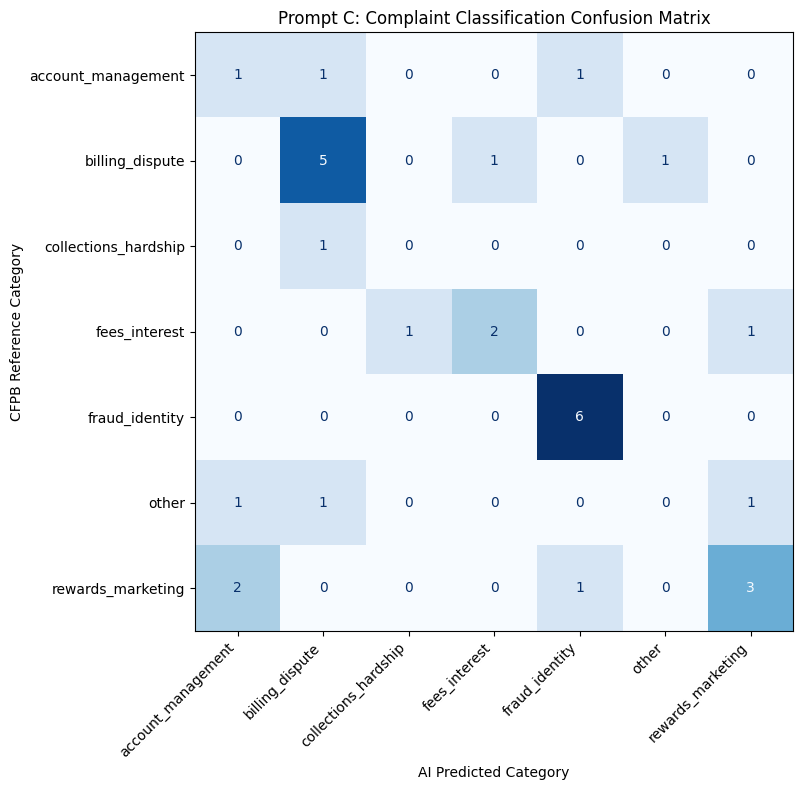

In [25]:
# Create confusion matrix for Prompt C

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Use the Prompt C evaluation results
actual = evaluation["category_actual"]
predicted = evaluation["category_predicted"]

# Create confusion matrix
fig, ax = plt.subplots(figsize=(12, 8))

ConfusionMatrixDisplay.from_predictions(
    actual,
    predicted,
    xticks_rotation=45,
    cmap="Blues",
    values_format="d",
    ax=ax,
    colorbar=False
)

plt.title("Prompt C: Complaint Classification Confusion Matrix")
plt.xlabel("AI Predicted Category")
plt.ylabel("CFPB Reference Category")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

# Save chart for Hunter
plt.savefig("Prompt_C_Confusion_Matrix.png", dpi=300)

plt.show()

In [26]:
# Compare category distribution in the full dataset and test sample

# Full dataset category counts
full_counts = df_clean["AI_Category"].value_counts()

# Hunter's 30 test complaints
test_counts = real_cases["category"].value_counts()

# Combine the results
category_comparison = pd.DataFrame({
    "Full Dataset Count": full_counts,
    "Test Sample Count": test_counts
}).fillna(0)

# Calculate percentages
category_comparison["Full Dataset %"] = (
    category_comparison["Full Dataset Count"] / len(df_clean) * 100
).round(1)

category_comparison["Test Sample %"] = (
    category_comparison["Test Sample Count"] / len(real_cases) * 100
).round(1)

# Arrange the table
category_comparison = category_comparison.sort_values(
    "Full Dataset Count", ascending=False
)

display(category_comparison)

# Save results for Hunter
category_comparison.to_csv("Category_Sample_Comparison.csv")

,Full Dataset Count,Test Sample Count,Full Dataset %,Test Sample %
billing_dispute,4239,7.0,23.2,23.3
account_management,3388,3.0,18.5,10.0
rewards_marketing,2366,6.0,12.9,20.0
fraud_identity,2254,6.0,12.3,20.0
fees_interest,2126,4.0,11.6,13.3
other,1890,3.0,10.3,10.0
collections_hardship,1067,1.0,5.8,3.3
customer_service,946,0.0,5.2,0.0


In [27]:
# Bootstrap confidence interval for Prompt C accuracy

import numpy as np

correct = (
    evaluation["category_actual"] ==
    evaluation["category_predicted"]
).astype(int).to_numpy()

rng = np.random.default_rng(42)

bootstrap_scores = [
    rng.choice(correct, size=len(correct), replace=True).mean()
    for _ in range(1000)
]

lower, upper = np.percentile(bootstrap_scores, [2.5, 97.5])

print(f"Prompt C Accuracy: {correct.mean():.1%}")
print(f"95% Bootstrap Confidence Interval: {lower:.1%} to {upper:.1%}")

Prompt C Accuracy: 56.7%
95% Bootstrap Confidence Interval: 40.0% to 73.3%


In [28]:
# Bootstrap confidence intervals for prompt in ["A", "B"]:

import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

for prompt in ["A", "B", "C"]:

    # Get saved AI predictions
    predictions = pd.DataFrame(
        ai_results[prompt]["classifications"]
    )

    predictions["id"] = predictions["id"].astype(str)

    # Match predictions with the 30 real complaints
    comparison = real_cases.merge(
        predictions[["id", "category"]],
        left_on="complaint_id",
        right_on="id",
        suffixes=("_actual", "_predicted"),
        validate="one_to_one"
    )

    assert len(comparison) == 30

    # Check correct classifications
    correct = (
        comparison["category_actual"] ==
        comparison["category_predicted"]
    ).astype(int).to_numpy()

    # Bootstrap 1,000 times
    bootstrap_scores = [
        rng.choice(correct, size=len(correct), replace=True).mean()
        for _ in range(1000)
    ]

    # Calculate confidence interval
    lower, upper = np.percentile(bootstrap_scores, [2.5, 97.5])

    print(f"Prompt {prompt}")
    print(f"Accuracy: {correct.mean():.1%}")
    print(f"95% Confidence Interval: {lower:.1%} to {upper:.1%}")
    print("----------------------------")

Prompt A
Accuracy: 43.3%
95% Confidence Interval: 26.7% to 60.0%
----------------------------
Prompt B
Accuracy: 46.7%
95% Confidence Interval: 26.7% to 63.3%
----------------------------
Prompt C
Accuracy: 56.7%
95% Confidence Interval: 39.9% to 76.7%
----------------------------


In [29]:
# Compare Prompt C against A and B using paired bootstrap

import numpy as np
import pandas as pd

test = real_cases[["complaint_id", "category"]].copy()
test = test.rename(columns={"category": "actual"})

for prompt in ["A", "B", "C"]:
    pred = pd.DataFrame(ai_results[prompt]["classifications"])
    pred["id"] = pred["id"].astype(str)

    test = test.merge(
        pred[["id", "category"]],
        left_on="complaint_id",
        right_on="id",
        validate="one_to_one"
    ).drop(columns="id")

    test = test.rename(columns={"category": f"pred_{prompt}"})

assert len(test) == 30

# Identify correct classifications
correct = {
    p: (test["actual"] == test[f"pred_{p}"]).astype(int).to_numpy()
    for p in ["A", "B", "C"]
}

# Resample the same complaints for each comparison
rng = np.random.default_rng(42)
samples = rng.integers(0, 30, size=(1000, 30))

for prompt in ["A", "B"]:
    differences = correct["C"] - correct[prompt]
    bootstrap = differences[samples].mean(axis=1)

    lower, upper = np.percentile(bootstrap, [2.5, 97.5])

    print(f"Prompt C vs {prompt}")
    print(f"Accuracy difference: {differences.mean():+.1%}")
    print(f"95% Confidence Interval: {lower:+.1%} to {upper:+.1%}")
    print("----------------------------")

Prompt C vs A
Accuracy difference: +13.3%
95% Confidence Interval: +3.3% to +26.7%
----------------------------
Prompt C vs B
Accuracy difference: +10.0%
95% Confidence Interval: -3.3% to +26.7%
----------------------------


In [30]:
# Non-AI baseline: Always predict the most common category

from sklearn.metrics import accuracy_score, f1_score

# Find the most common category in the full dataset
most_common = df_clean["AI_Category"].mode()[0]

# Predict that category for all 30 test complaints
baseline_predictions = [most_common] * len(real_cases)

# Calculate accuracy
baseline_accuracy = accuracy_score(
    real_cases["category"],
    baseline_predictions
)

# Calculate Macro F1 using all 8 categories
baseline_f1 = f1_score(
    real_cases["category"],
    baseline_predictions,
    labels=list(CATEGORY_ISSUES.keys()),
    average="macro",
    zero_division=0
)

print("Most common category:", most_common)
print(f"Baseline Accuracy: {baseline_accuracy:.1%}")
print(f"Baseline Macro F1: {baseline_f1:.3f}")

Most common category: billing_dispute
Baseline Accuracy: 23.3%
Baseline Macro F1: 0.047
